# 01. HydroCNHS Watershed Hydrology & Inflows

- **Step 1 of 4:** Configure catchment hydrology (`hydrology.yaml` + `xindian_catchments.yaml`) and produce non-overlapping `inflows.csv`.
- **Case (Repo-Only — Not in Paper):** Taiwan Xindian River (`U1, U2, D1, D2`; TFRA `145840` rain + ERA5 temp/PET, MOEA/WRA gauges).
- **Pass Criterion:** `0` overlapping subbasins; HydroCNHS parity within `1e-5 m3/s`.

In [1]:
from pathlib import Path
import sys
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

for p in (Path.cwd(), *Path.cwd().parents):
    if (p / "tutorials" / "_helpers.py").is_file():
        sys.path.insert(0, str(p))
        break
from tutorials import _helpers as h
from llm_reservoir_agent.weather import load_weather, simulate_weather, validate_bindings

REPO_ROOT = h.find_repo_root()
C = h.configure_plots()

## 1. Inspect `hydrology.yaml` & Verify Non-Overlapping Bindings

`hydrology.yaml` maps HydroCNHS subbasins (`U1–U2` Beishi, `D1–D2` Nanshi) to reservoir inlet nodes without double-counting upstream flow.

In [2]:
mr_dir = REPO_ROOT / "examples" / "multi_reservoir"
hyd_dir = mr_dir / "hydrology"
hyd_spec = yaml.safe_load((hyd_dir / "hydrology.yaml").read_text(encoding="utf-8"))
weather = load_weather(hyd_spec, hyd_dir)
unused = validate_bindings(weather, routing_nodes=["feitsui_local", "zhitan_local", "xindian_outlet"])

print(f"Forcing window : {weather['dates'][0]} to {weather['dates'][-1]} ({len(weather['dates'])} days)")
print(f"Subbasins      : {weather['units']} | Unused units: {unused} (0 overlap OK)")
print("Bindings       :", hyd_spec["inflow_bindings"])

Forcing window : 2015-01-01 to 2025-12-31 (4018 days)
Subbasins      : ['U1', 'U2', 'D1', 'D2'] | Unused units: [] (0 overlap OK)
Bindings       : {'feitsui_local': {'routed': 'U1'}, 'zhitan_local': {'routed': 'D1'}, 'xindian_outlet': {'constant': 0}}


## 2. Run Native HydroCNHS & Check 10-Year C&V Parity

Run `simulate_weather` (`GWLF + Lohmann`), verify parity against `inflows.csv`, and score out-of-sample `2023–2025` flows.

In [3]:
sim_res = simulate_weather(weather, REPO_ROOT)
sim_df = pd.DataFrame({"date": weather["dates"], "feitsui_sim": sim_res["routed"]["U1"], "zhitan_sim": sim_res["routed"]["D1"]})
pub = pd.read_csv(mr_dir / "inflows.csv").pivot(index="date", columns="node", values="local_inflow_cms").reset_index()
chk = pub.merge(sim_df, on="date", how="inner")
print(f"Coupling max |diff| : feitsui={np.max(np.abs(chk['feitsui_local']-chk['feitsui_sim'])):.2e}, zhitan={np.max(np.abs(chk['zhitan_local']-chk['zhitan_sim'])):.2e} m3/s")

obs_cv = pd.read_csv(hyd_dir / "cv_observations.csv.gz")
m_val = sim_df.merge(obs_cv, on="date", how="inner")
m_val["date_dt"] = pd.to_datetime(m_val["date"])
val = m_val[(m_val["date"] >= "2023-01-01") & (m_val["date"] <= "2025-12-31")]
sc_f = h.kge_components(val["feitsui_sim"], val["feitsui_inflow_cms"])
sc_n = h.kge_components(val["zhitan_sim"], val["zhitan_local_nanshi_cms"])
print("2023-2025 Validation Feitsui :", {k: round(v, 3) for k, v in sc_f.items()})
print("2023-2025 Validation Nanshi  :", {k: round(v, 3) for k, v in sc_n.items()})


Coupling max |diff| : feitsui=4.96e-07, zhitan=5.00e-07 m3/s
2023-2025 Validation Feitsui : {'kge': 0.912, 'r': 0.948, 'alpha': 1.061, 'beta': 1.037, 'nse': 0.886, 'rmse': 17.378}
2023-2025 Validation Nanshi  : {'kge': 0.844, 'r': 0.849, 'alpha': 1.039, 'beta': 0.991, 'nse': 0.684, 'rmse': 32.856}


## 3. Visualize 10-Year Hydrographs & Flow-Duration Skill

Compare calibration (`2016–2022`) and validation (`2023–2025`) hydrographs, `KGE (r, alpha, beta)` skill, and flow-duration curves.

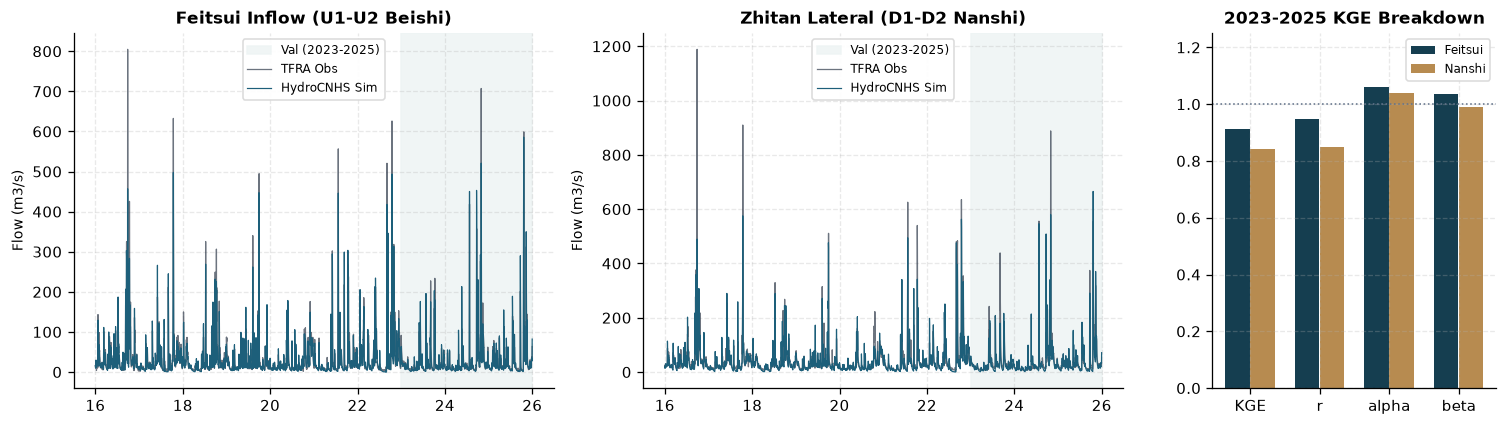

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8), gridspec_kw={"width_ratios": [2.2, 2.2, 1.3]})
for ax, col_s, col_o, ttl in [
    (axes[0], "feitsui_sim", "feitsui_inflow_cms", "Feitsui Inflow (U1-U2 Beishi)"),
    (axes[1], "zhitan_sim", "zhitan_local_nanshi_cms", "Zhitan Lateral (D1-D2 Nanshi)"),
]:
    ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2025-12-31"), color="#eef4f4", alpha=0.85, label="Val (2023-2025)")
    ax.plot(m_val["date_dt"], m_val[col_o], color=C["obs"], lw=0.8, alpha=0.65, label="TFRA Obs")
    ax.plot(m_val["date_dt"], m_val[col_s], color=C["teal"], lw=0.75, label="HydroCNHS Sim")
    ax.set_title(ttl); ax.set_ylabel("Flow (m3/s)"); ax.legend(fontsize=7.5)
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%y"))
x = np.arange(4)
axes[2].bar(x - 0.18, [sc_f["kge"], sc_f["r"], sc_f["alpha"], sc_f["beta"]], 0.35, color=C["navy"], label="Feitsui")
axes[2].bar(x + 0.18, [sc_n["kge"], sc_n["r"], sc_n["alpha"], sc_n["beta"]], 0.35, color=C["gold"], label="Nanshi")
axes[2].axhline(1.0, color=C["muted"], ls=":", lw=1.0); axes[2].set_xticks(x, ["KGE", "r", "alpha", "beta"])
axes[2].set_ylim(0, 1.25); axes[2].set_title("2023-2025 KGE Breakdown"); axes[2].legend(fontsize=7.5)
plt.tight_layout(); plt.show()

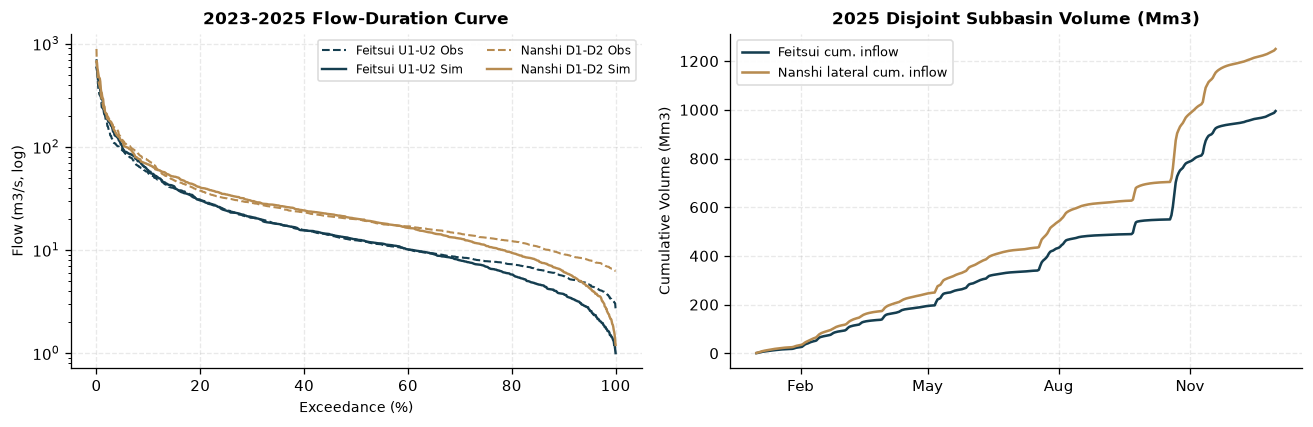

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
p_grid = np.linspace(0, 100, len(val))
for label, s_c, o_c, col in [("Feitsui U1-U2", "feitsui_sim", "feitsui_inflow_cms", C["navy"]),
                              ("Nanshi D1-D2", "zhitan_sim", "zhitan_local_nanshi_cms", C["gold"])]:
    axes[0].plot(p_grid, np.sort(val[o_c])[::-1], color=col, ls="--", lw=1.3, label=f"{label} Obs")
    axes[0].plot(p_grid, np.sort(val[s_c])[::-1], color=col, lw=1.5, label=f"{label} Sim")
axes[0].set_yscale("log"); axes[0].set_title("2023-2025 Flow-Duration Curve"); axes[0].set_xlabel("Exceedance (%)"); axes[0].set_ylabel("Flow (m3/s, log)"); axes[0].legend(fontsize=7.5, ncol=2)

sub25 = chk[chk["date"] >= "2025-01-01"].copy()
sub25["dt"] = pd.to_datetime(sub25["date"])
axes[1].plot(sub25["dt"], sub25["feitsui_local"].cumsum() * 86400 / 1e6, color=C["navy"], lw=1.6, label="Feitsui cum. inflow")
axes[1].plot(sub25["dt"], sub25["zhitan_local"].cumsum() * 86400 / 1e6, color=C["gold"], lw=1.6, label="Nanshi lateral cum. inflow")
axes[1].set_title("2025 Disjoint Subbasin Volume (Mm3)"); axes[1].set_ylabel("Cumulative Volume (Mm3)"); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout(); plt.show()